# Digital Detective: Feature Extraction Challenge
Target object: a box of Bastoncini almond cookies.
Cluttered scene: the same box on a chair with other boxes and a plastic bag.
Use ORB to find features and match them between the two images.

# **TEE HONG XUAN**
## **A25AI0046**
### **Section 3**

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def show_img(title, img):
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

## Step 1: Load and Prepare Images
Upload `Box.png` and `Scene.png` before running this cell.

Image source: OpenCV sample data (`box.png` and `box_in_scene.png`).
https://github.com/opencv/opencv/tree/4.x/samples/data

Box size: (223, 324, 3)
Scene size: (384, 512, 3)


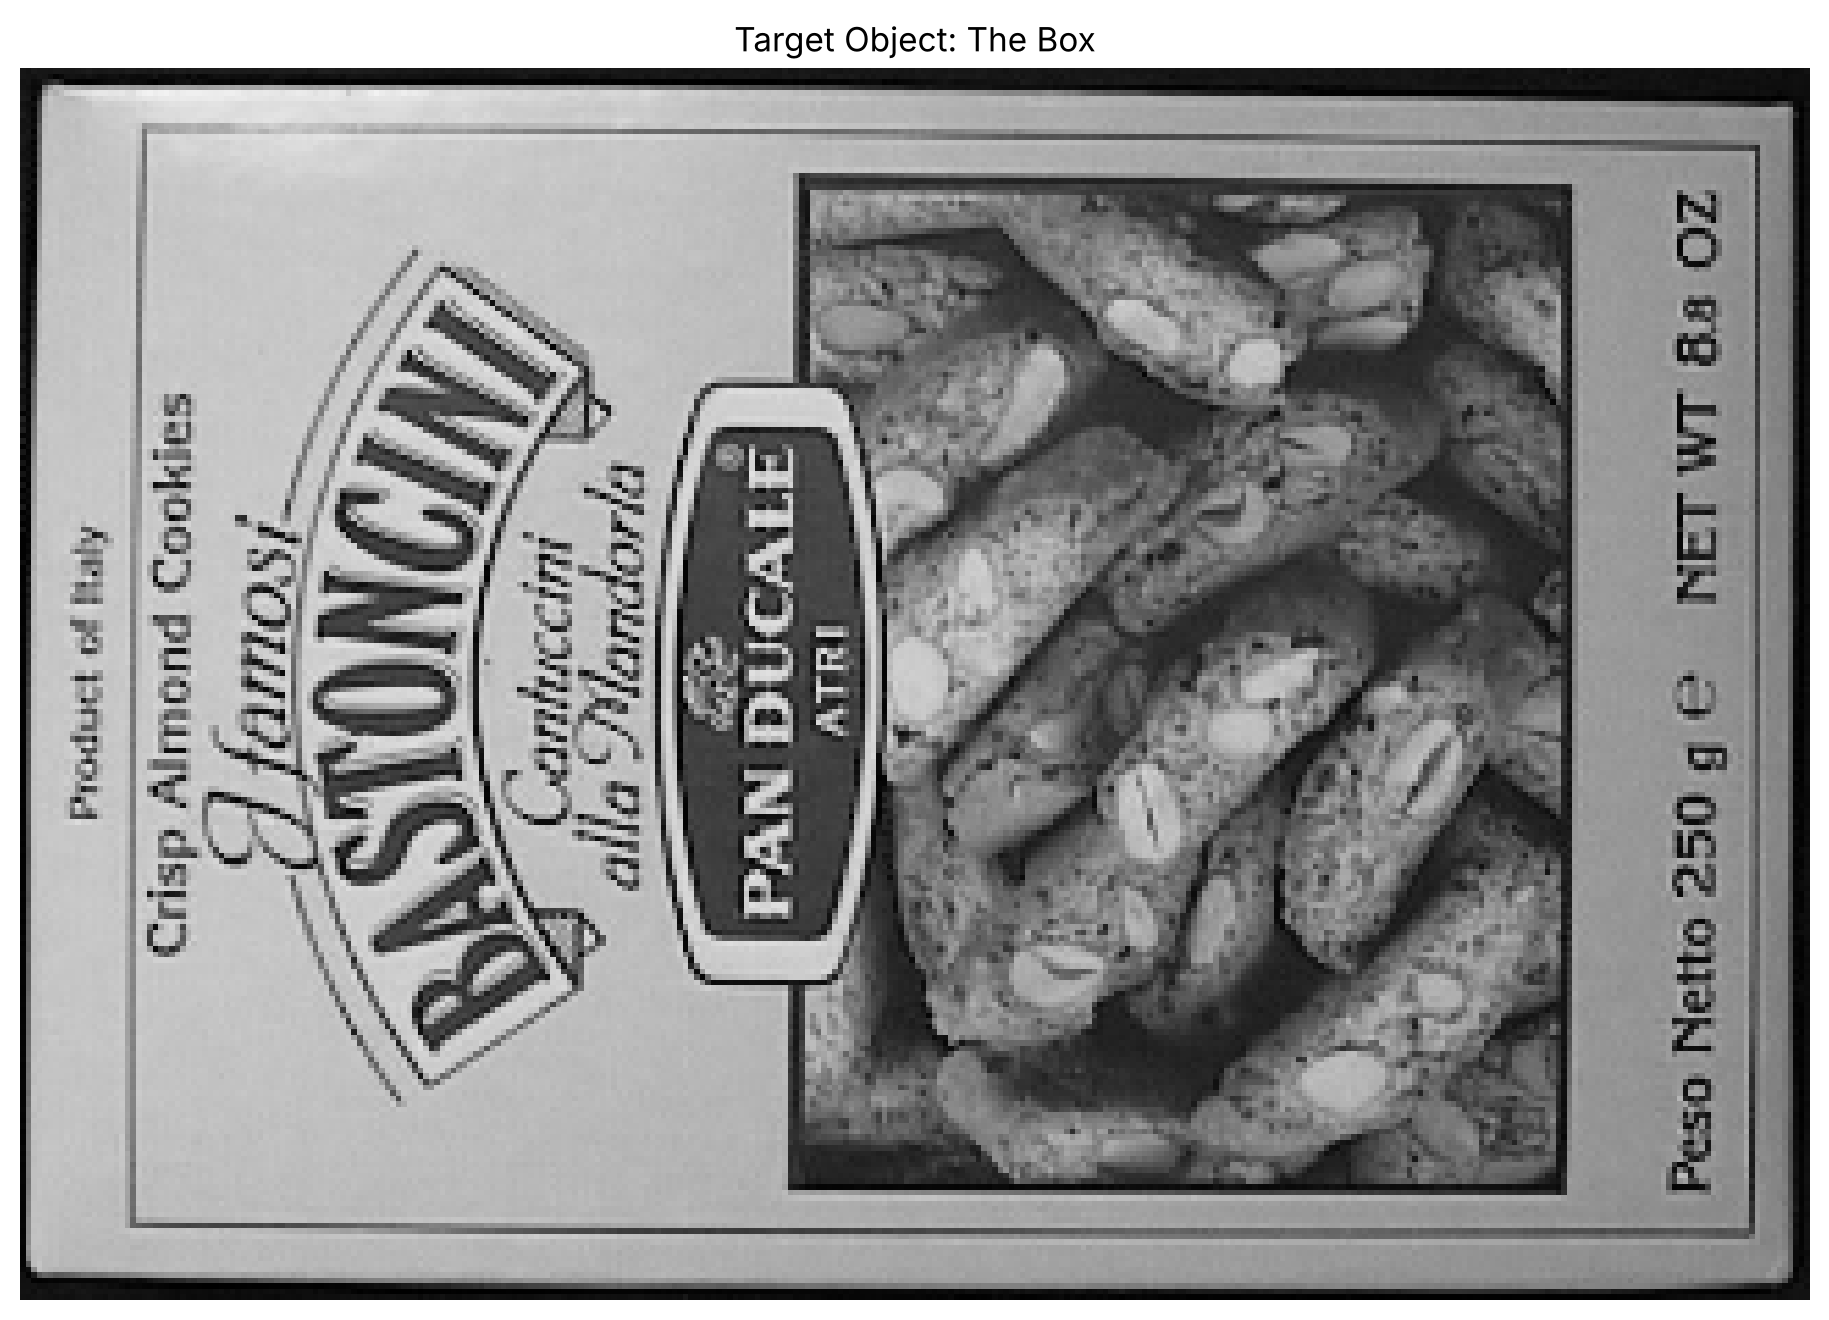

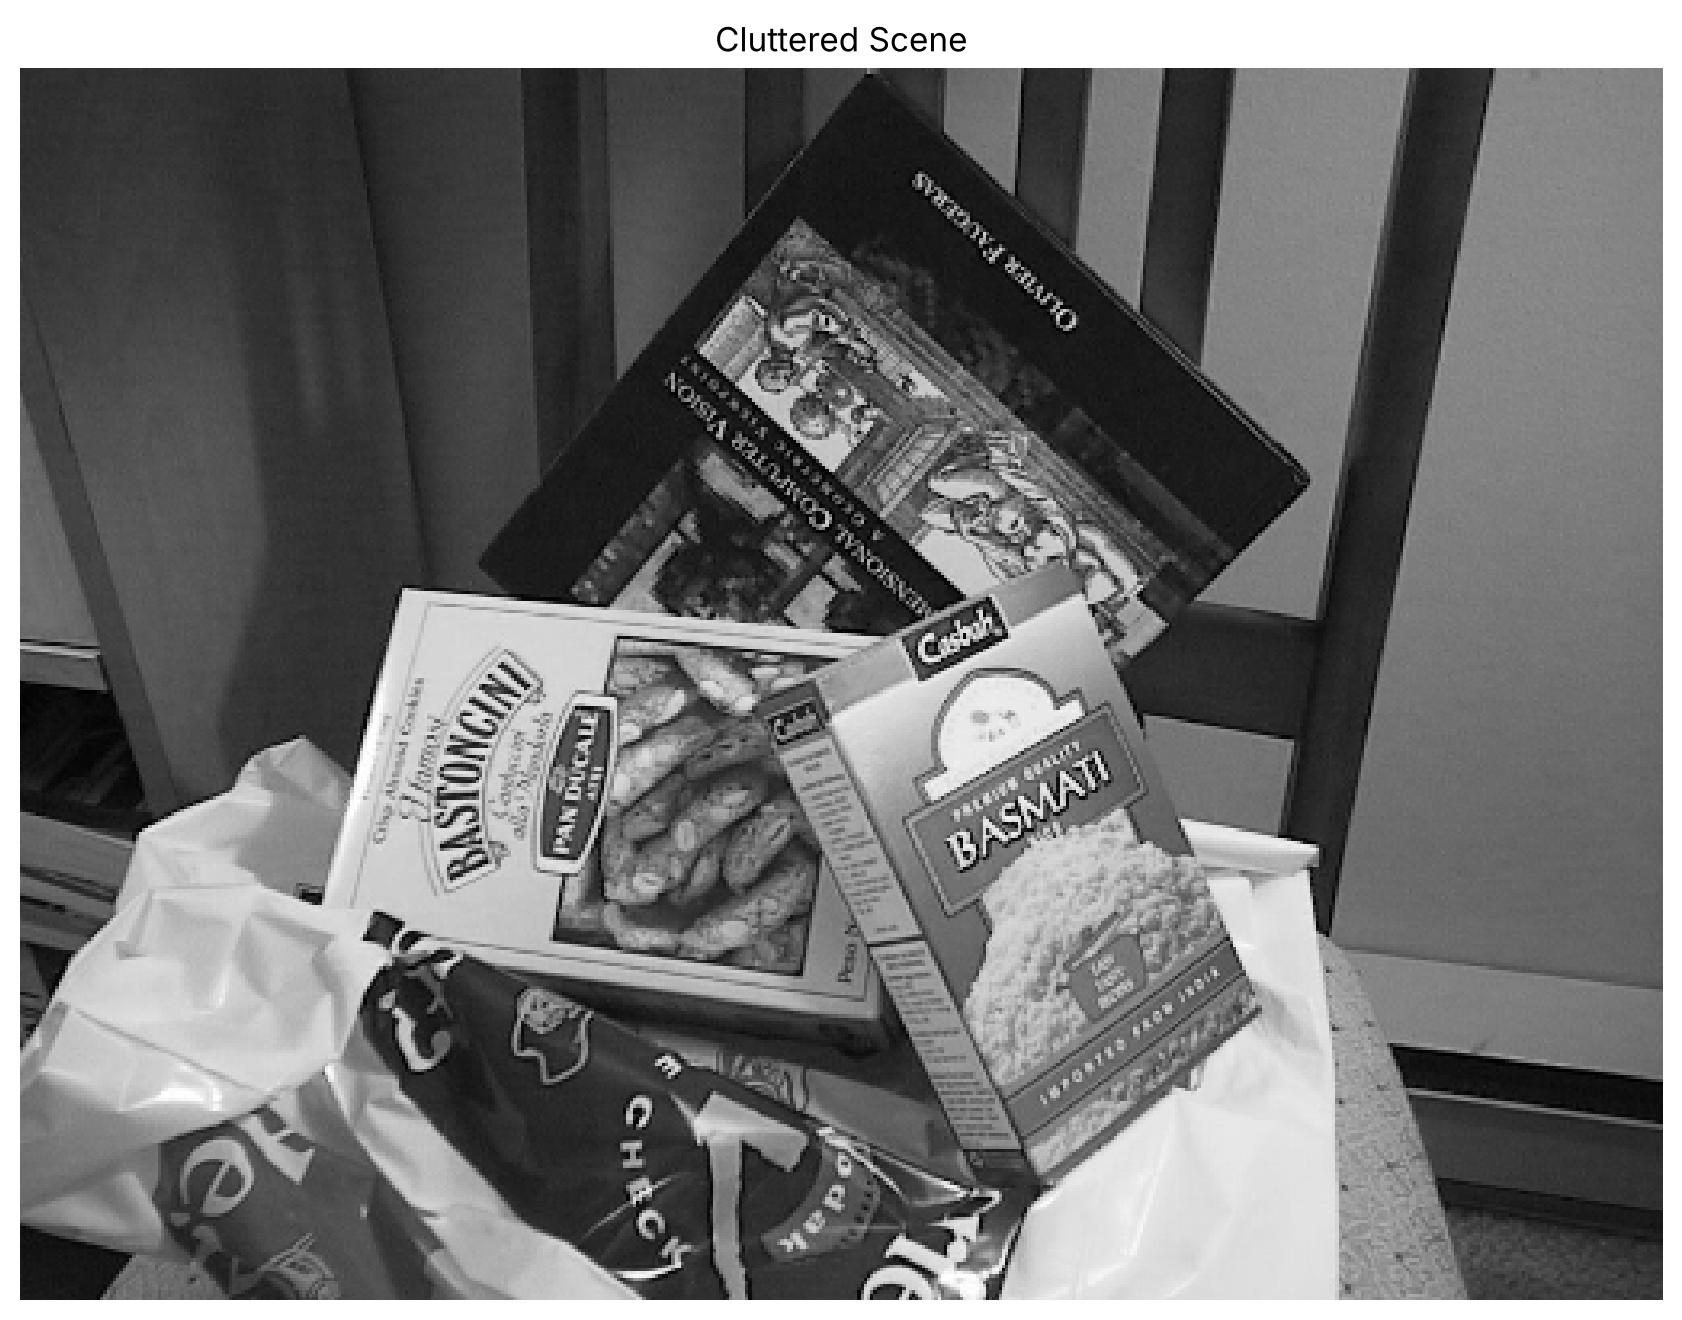

In [ ]:
img_box = cv2.imread('Box.png')
img_scene = cv2.imread('Scene.png')

gray_box = cv2.cvtColor(img_box, cv2.COLOR_BGR2GRAY)
gray_scene = cv2.cvtColor(img_scene, cv2.COLOR_BGR2GRAY)

print("Box size:", img_box.shape)
print("Scene size:", img_scene.shape)
show_img("Target Object: The Box", img_box)
show_img("Cluttered Scene", img_scene)

## Mission 1: Training the Computer
### Observe the Target Image
The box has big curved logo text and an oval badge.
It also has a photo of cookies with a lot of texture.
The photo has a dark frame with sharp corners and straight edges.

### Top 5 Distinctive Features
| No. | Feature | Type |
|---|---|---|
| 1 | Top-left corner of the cookie photo | Corner |
| 2 | "PAN DUCALE" oval badge | Blob |
| 3 | Almond cookie pattern | Texture |
| 4 | "BASTONCINI" logo text | Text / pattern |
| 5 | Bottom edge of the cookie photo | Straight edge |

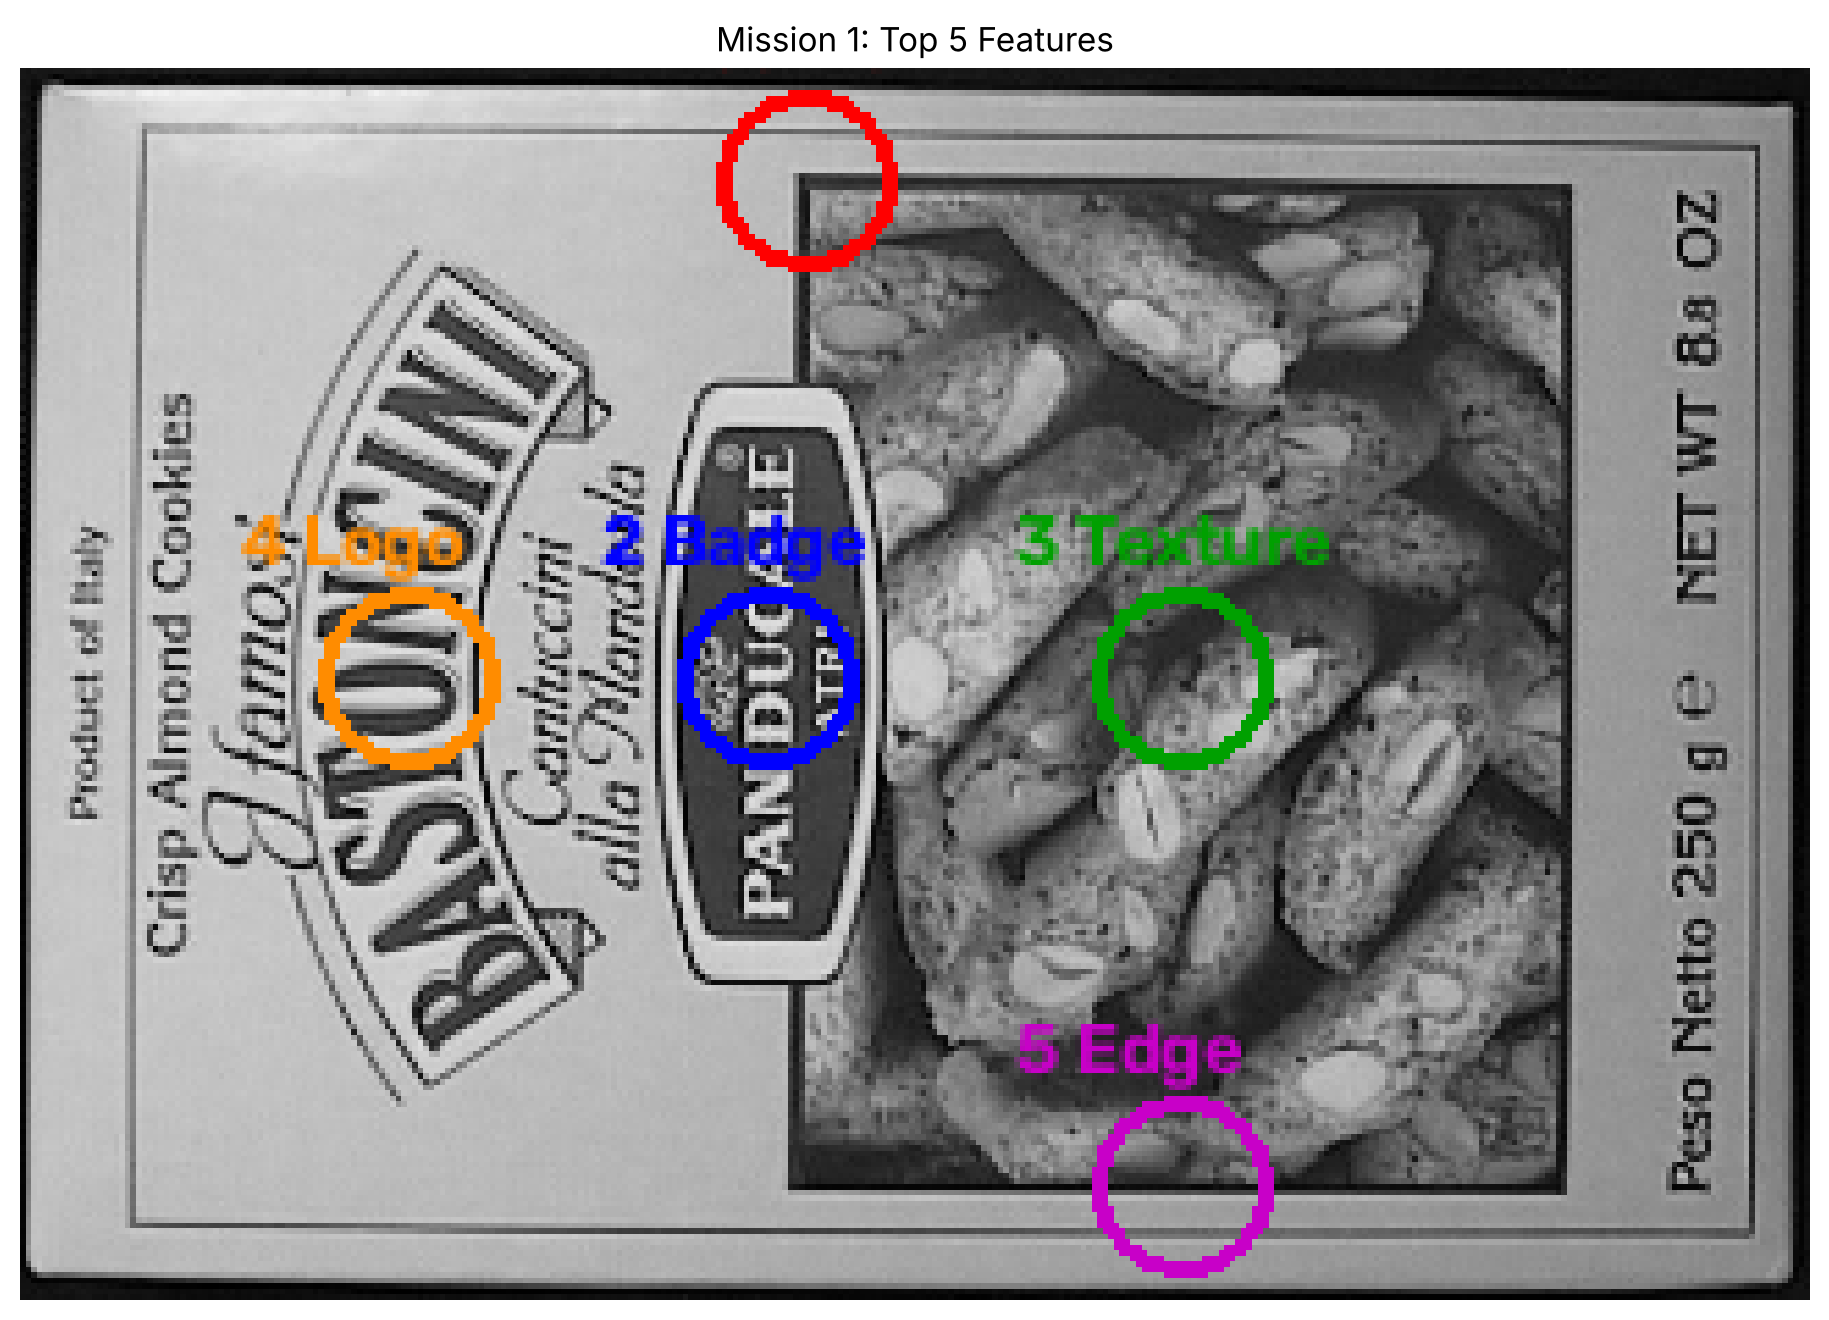

In [ ]:
features = [(142, 20), (135, 110), (210, 110), (70, 110), (210, 202)]
names = ["1 Corner", "2 Badge", "3 Texture", "4 Logo", "5 Edge"]
colors = [(0, 0, 255), (255, 0, 0), (0, 160, 0), (0, 140, 255), (200, 0, 200)]

img_marked = img_box.copy()
for (x, y), name, c in zip(features, names, colors):
    cv2.circle(img_marked, (x, y), 15, c, 2)
    cv2.putText(img_marked, name, (x - 30, y - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 2)

show_img("Mission 1: Top 5 Features", img_marked)

## Step 2: Extract Features using ORB
ORB finds keypoints by itself.
Most of them are on corners, letters and the cookie texture.

Keypoints in box: 453
Keypoints in scene: 500


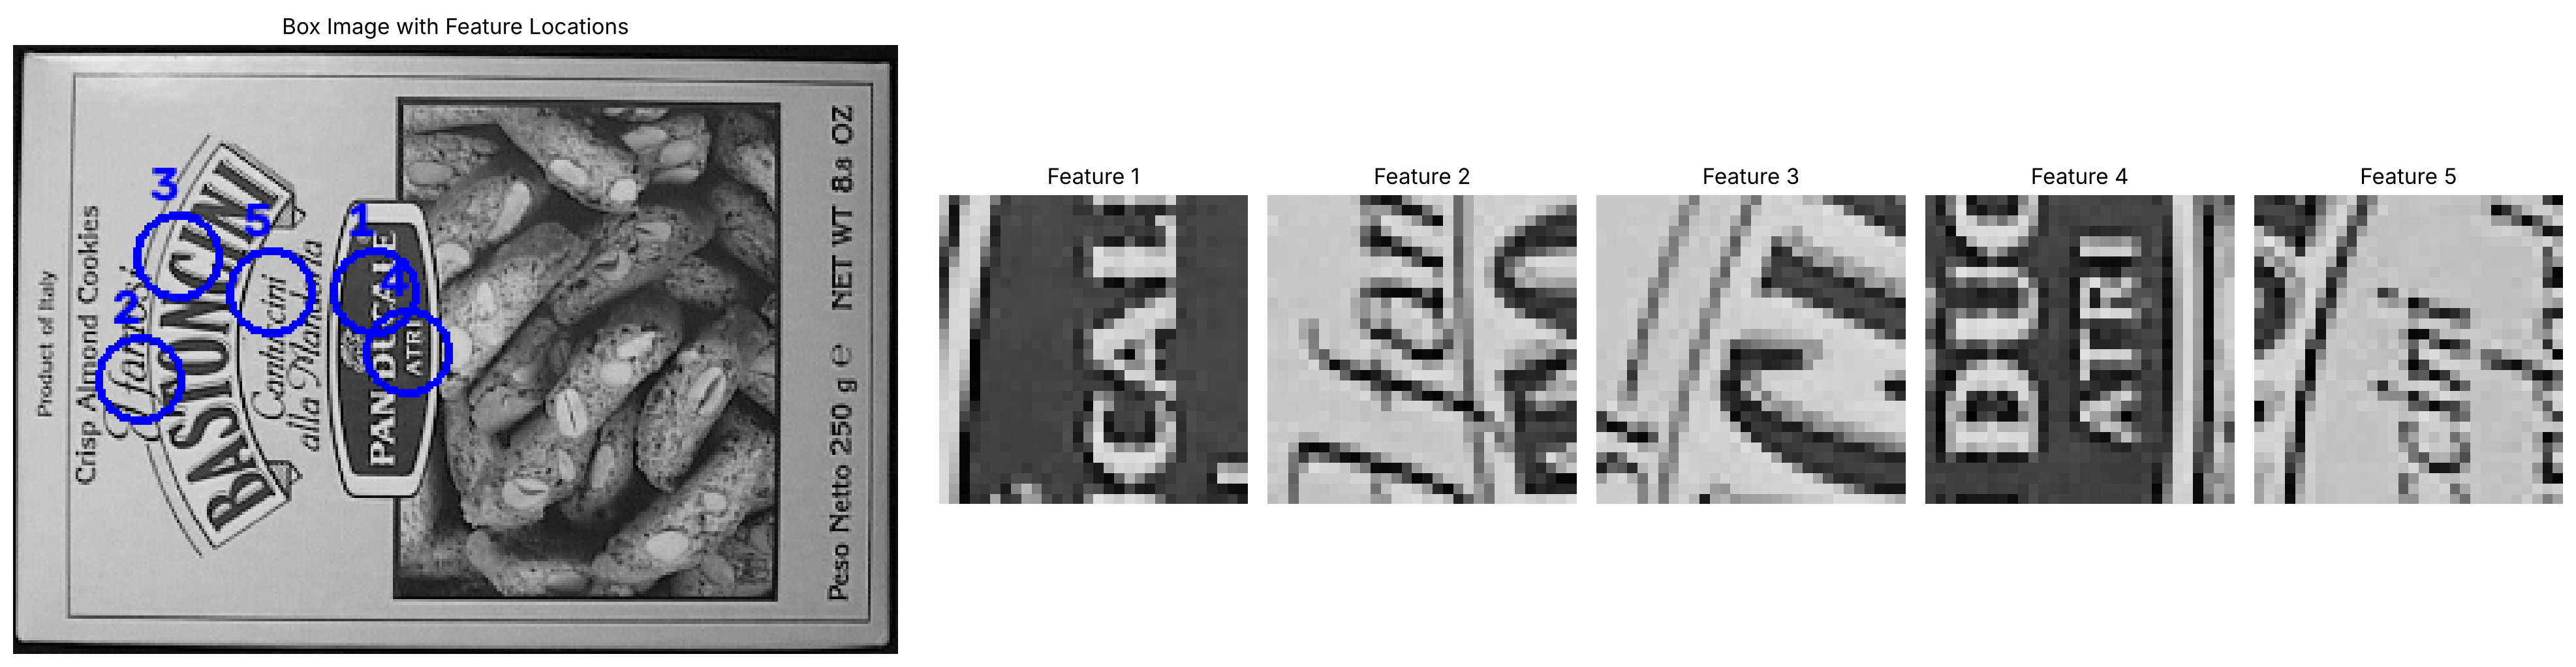

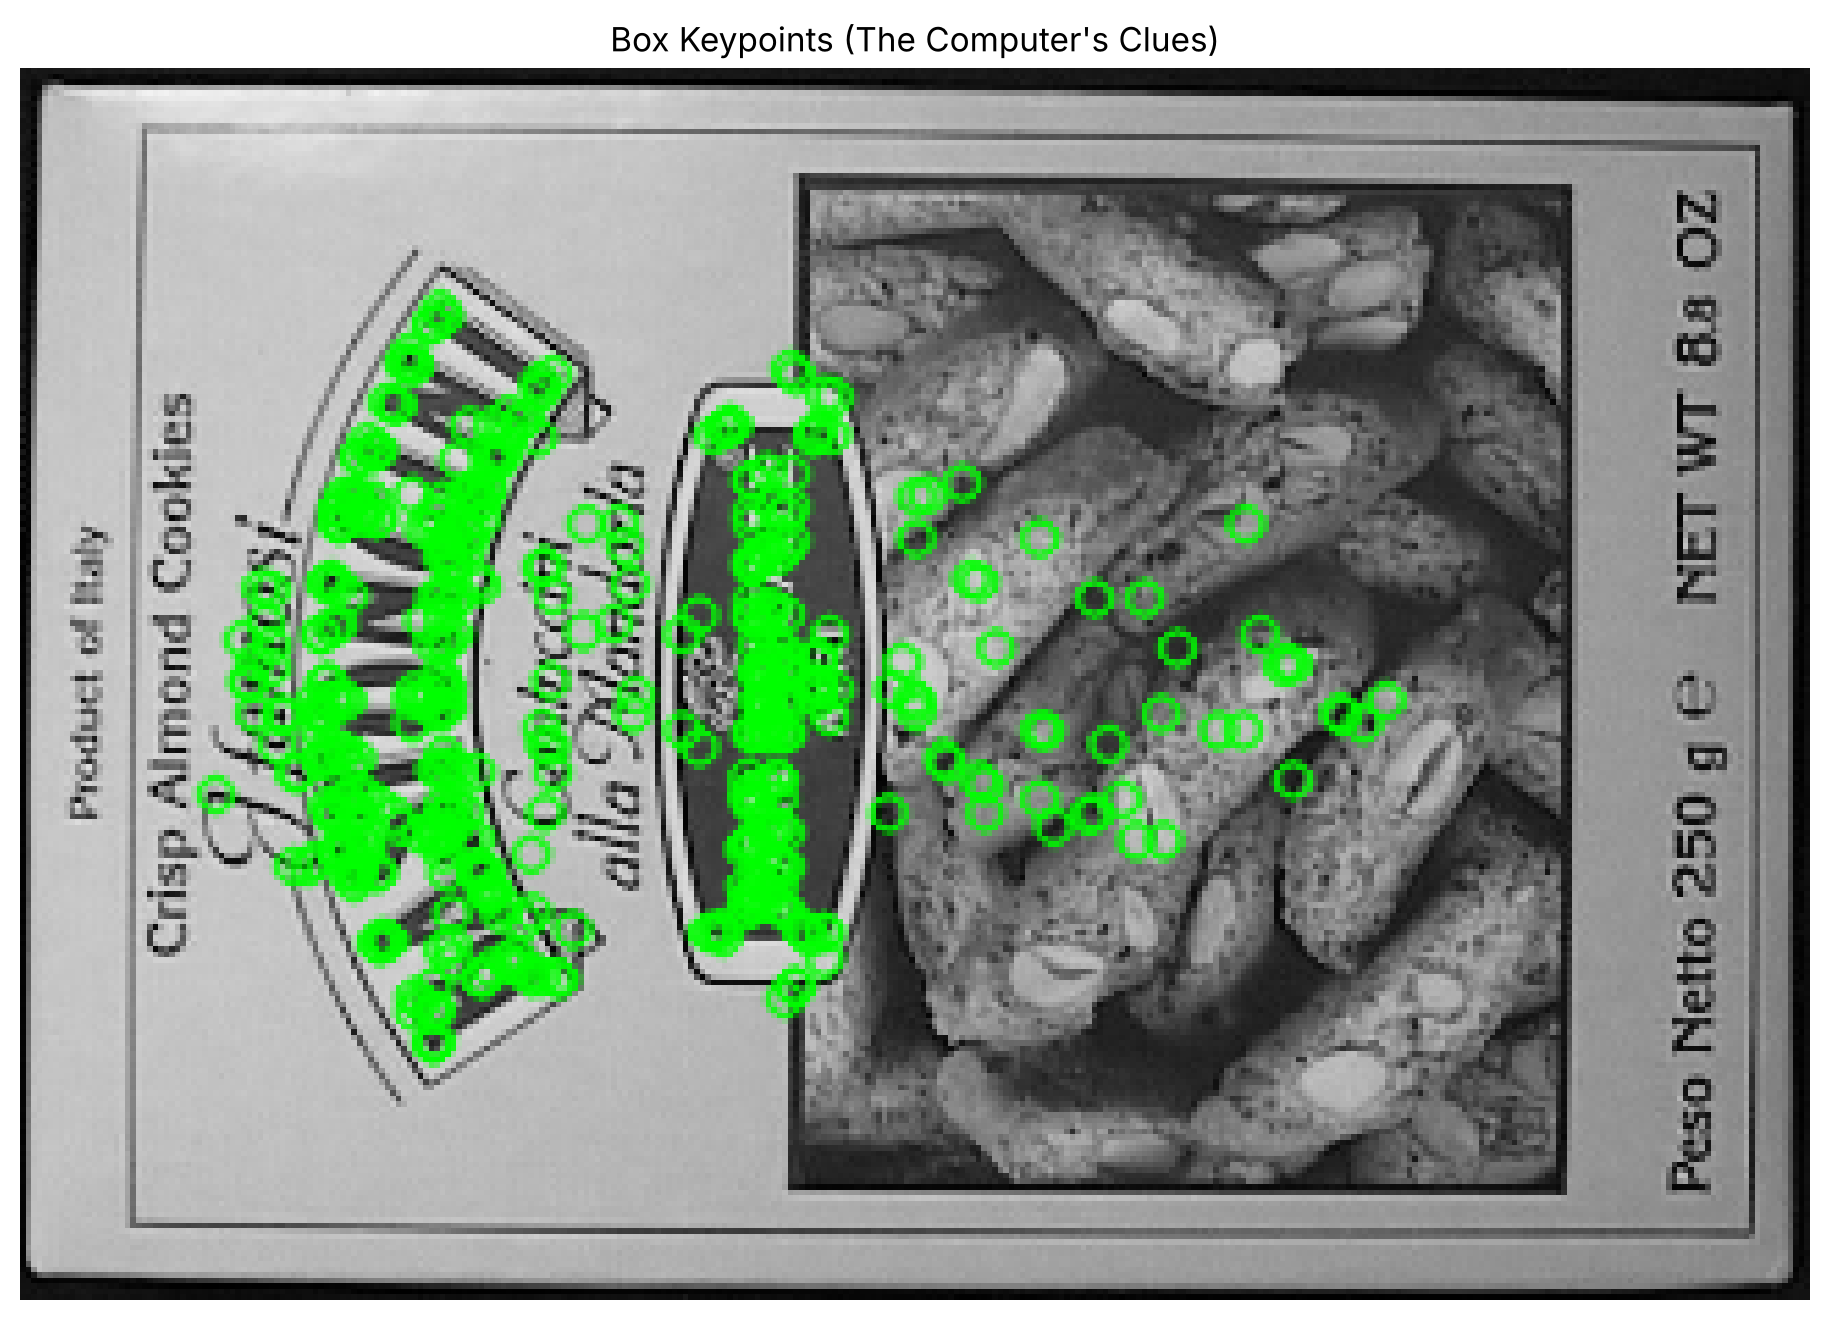

In [ ]:
orb = cv2.ORB_create(nfeatures=500)
kp_box, des_box = orb.detectAndCompute(gray_box, None)
kp_scene, des_scene = orb.detectAndCompute(gray_scene, None)

print("Keypoints in box:", len(kp_box))
print("Keypoints in scene:", len(kp_scene))

fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})
img_box_annotated = img_box.copy()
offset = 15

for i in range(5):
    x, y = int(kp_box[i].pt[0]), int(kp_box[i].pt[1])
    cv2.circle(img_box_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_box_annotated, str(i + 1), (x - 10, y - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    patch = img_box[max(0, y - offset):y + offset, max(0, x - offset):x + offset]
    axes[i + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(f"Feature {i + 1}")
    axes[i + 1].axis('off')

axes[0].imshow(cv2.cvtColor(img_box_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Box Image with Feature Locations")
axes[0].axis('off')
plt.tight_layout()
plt.show()

img_box_kp = cv2.drawKeypoints(img_box, kp_box, None, color=(0, 255, 0), flags=0)
show_img("Box Keypoints (The Computer's Clues)", img_box_kp)

## Mission 2: The Testing Phase
### Match Our 5 Features
We search the scene for each of our 5 features.
Then we draw a line from the box to the same spot in the scene.

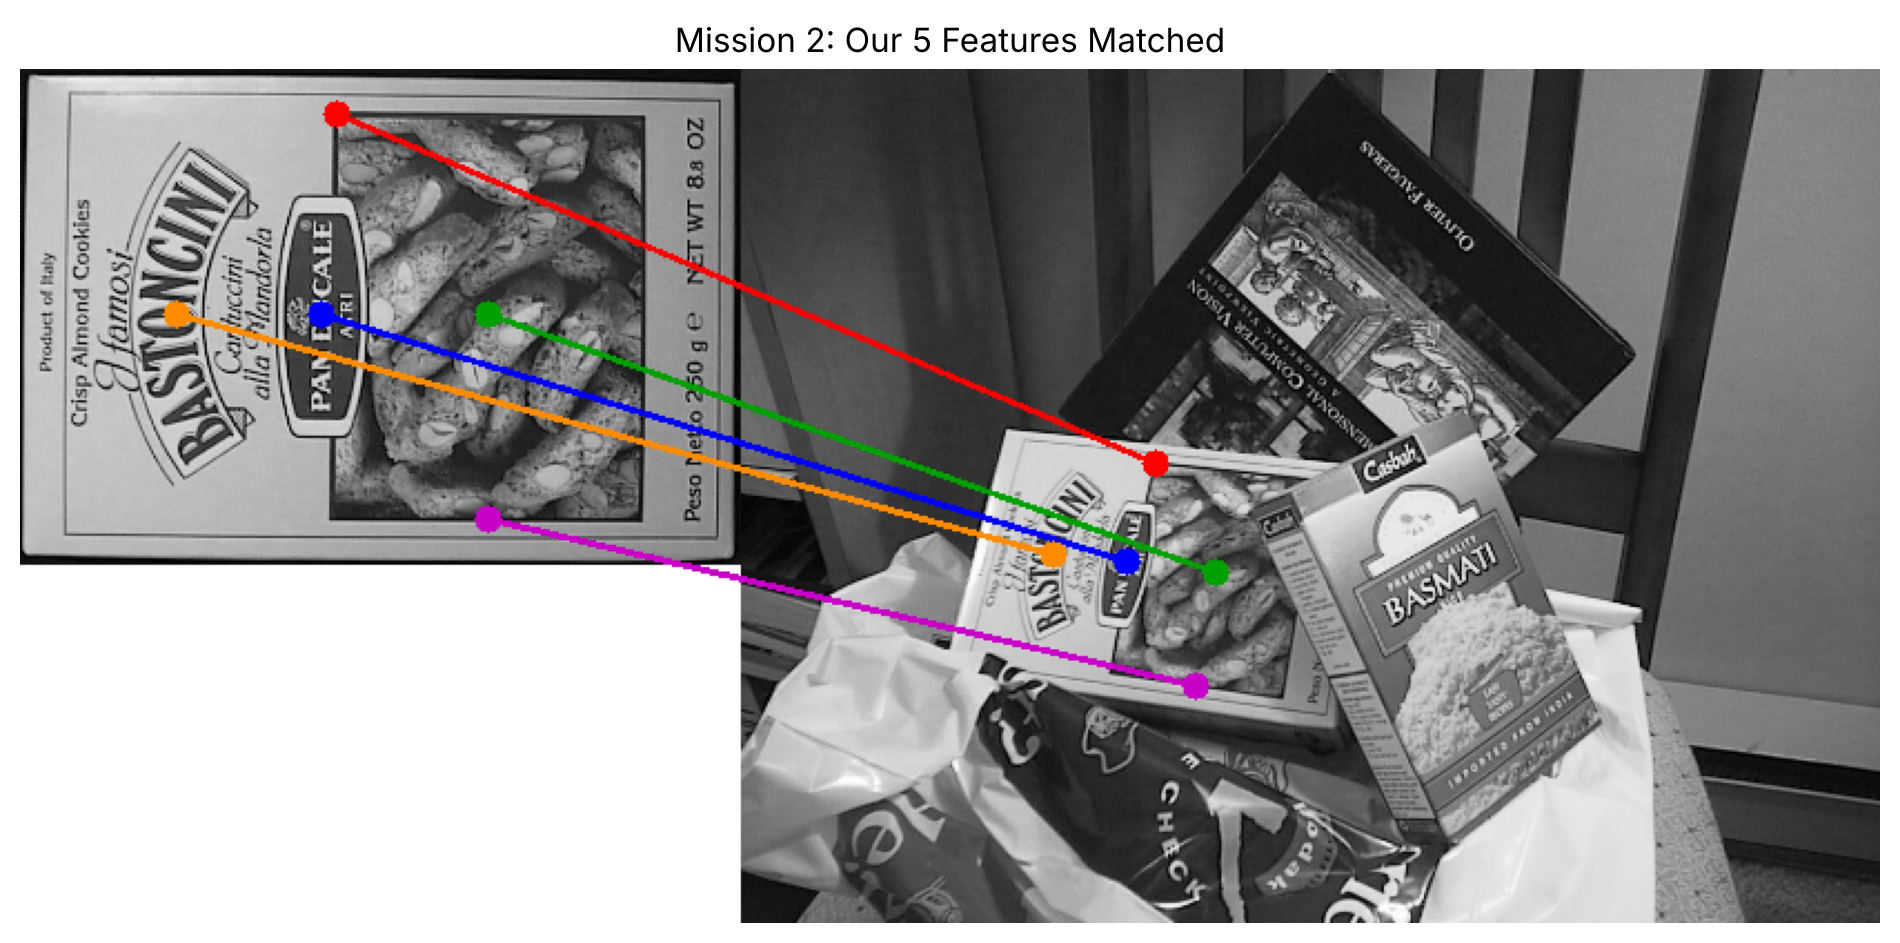

In [ ]:
scene_points = [(186, 177), (173, 221), (213, 226), (140, 218), (204, 277)]

h = img_scene.shape[0]
box_pad = cv2.copyMakeBorder(img_box, 0, h - img_box.shape[0], 0, 0, cv2.BORDER_CONSTANT, value=(255, 255, 255))
combined = np.hstack([box_pad, img_scene])
w = img_box.shape[1]

for (x1, y1), (x2, y2), name, c in zip(features, scene_points, names, colors):
    cv2.circle(combined, (x1, y1), 6, c, -1)
    cv2.circle(combined, (x2 + w, y2), 6, c, -1)
    cv2.line(combined, (x1, y1), (x2 + w, y2), c, 2)

show_img("Mission 2: Our 5 Features Matched", combined)

## Step 3: Match Features with ORB
The computer compares the box descriptors with the scene descriptors.

Total features matched: 148


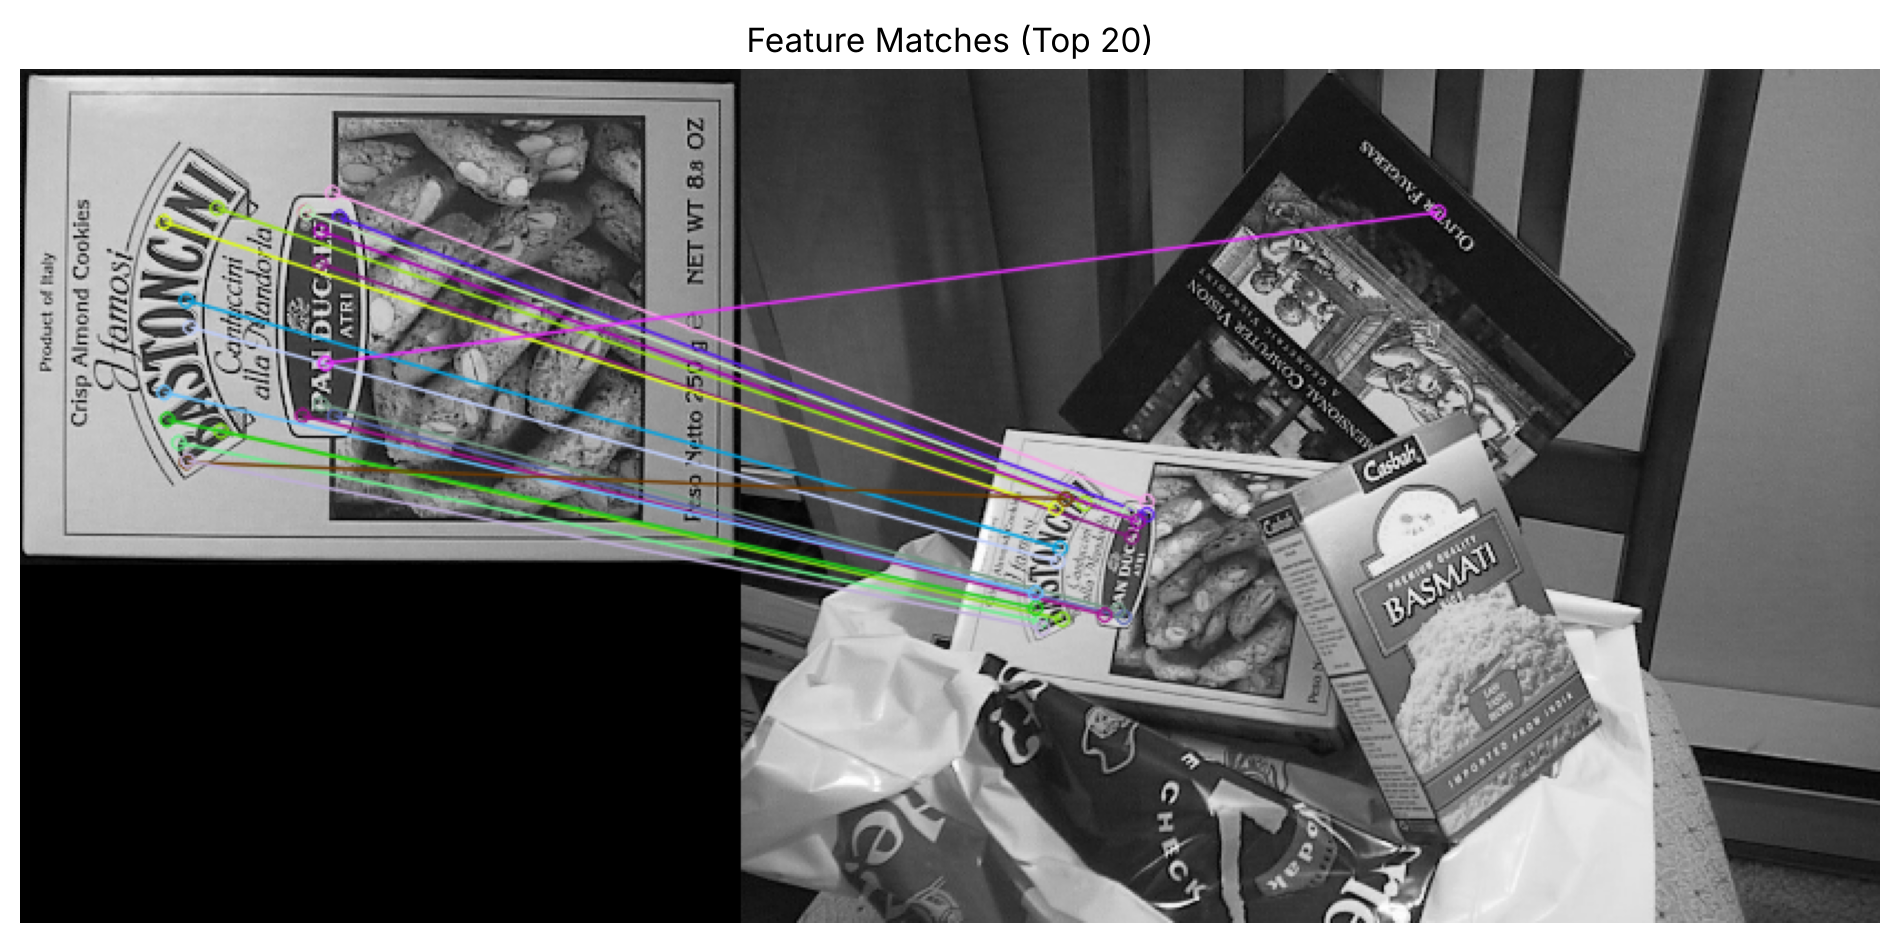

In [ ]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des_box, des_scene)
matches = sorted(matches, key=lambda x: x.distance)

print("Total features matched:", len(matches))

img_matches = cv2.drawMatches(img_box, kp_box, img_scene, kp_scene, matches[:20], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_img("Feature Matches (Top 20)", img_matches)

Correct matches: 22 out of 30


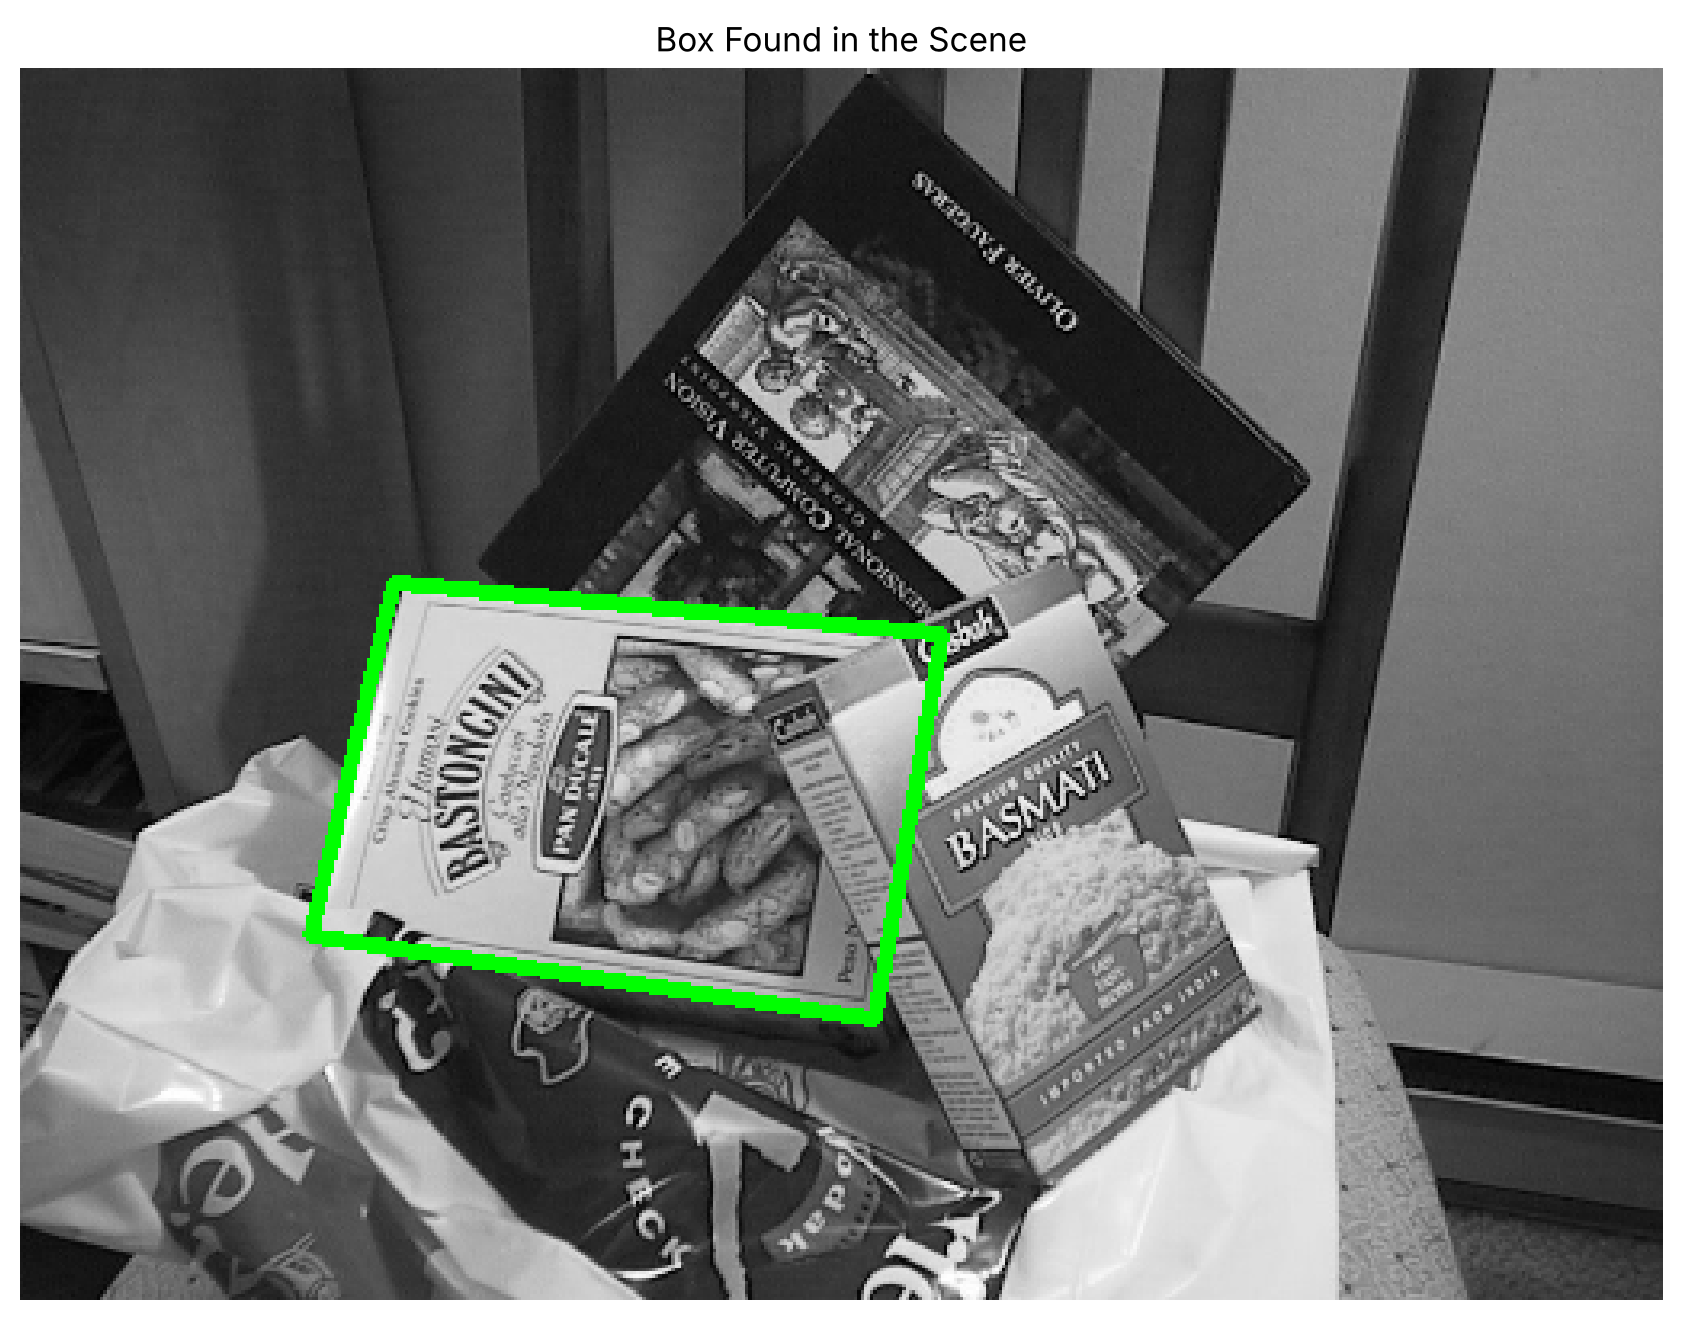

In [ ]:
good = matches[:30]
src = np.float32([kp_box[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst = np.float32([kp_scene[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)

print("Correct matches:", int(mask.sum()), "out of", len(good))

h_box, w_box = gray_box.shape
corners = np.float32([[0, 0], [w_box, 0], [w_box, h_box], [0, h_box]]).reshape(-1, 1, 2)
found = cv2.perspectiveTransform(corners, H)
img_found = cv2.polylines(img_scene.copy(), [np.int32(found)], True, (0, 255, 0), 3)
show_img("Box Found in the Scene", img_found)

## Step 4: Evaluate Reliability
**Easiest to match:** the logo text (4) and the badge (2).
They have strong black and white patterns.
Nothing else in the scene looks like them.

**Ambiguous:** the corner (1) and the straight edge (5).
Every box in the scene has corners and straight edges.
The Basmati box and the book can give false matches.

**Why some work better:** good features are unique and easy to find again.
Text and badges are unique.
Corners and edges are common everywhere.
The cookie texture (3) works, but some of it is hidden behind the Basmati box.

## Robustness Test
We rotate the box and change the lighting.
Then we count how many correct matches are still found in the scene.

Original | keypoints: 453 | correct matches: 22 / 30
Rotated 45 | keypoints: 459 | correct matches: 23 / 30
Dark | keypoints: 386 | correct matches: 24 / 30
Bright | keypoints: 449 | correct matches: 17 / 30


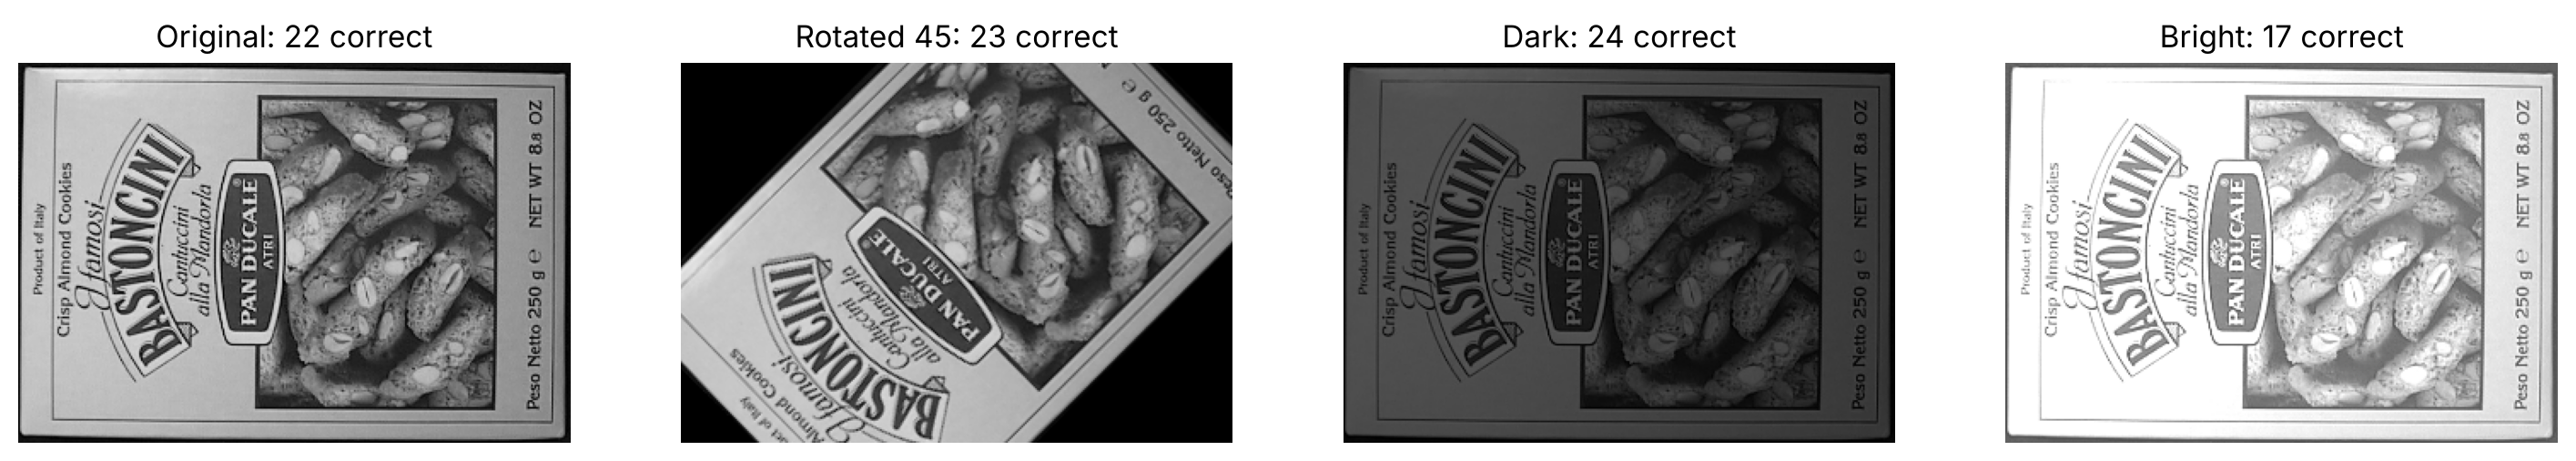

In [ ]:
h_box, w_box = img_box.shape[:2]
M = cv2.getRotationMatrix2D((w_box / 2, h_box / 2), 45, 1)

tests = {
    "Original": img_box,
    "Rotated 45": cv2.warpAffine(img_box, M, (w_box, h_box)),
    "Dark": cv2.convertScaleAbs(img_box, alpha=0.4, beta=0),
    "Bright": cv2.convertScaleAbs(img_box, alpha=1.0, beta=80),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, img) in zip(axes, tests.items()):
    kp, des = orb.detectAndCompute(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), None)
    m = sorted(bf.match(des, des_scene), key=lambda x: x.distance)[:30]
    src = np.float32([kp[x.queryIdx].pt for x in m]).reshape(-1, 1, 2)
    dst = np.float32([kp_scene[x.trainIdx].pt for x in m]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    print(name, "| keypoints:", len(kp), "| correct matches:", int(mask.sum()), "/ 30")
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}: {int(mask.sum())} correct")
    ax.axis('off')
plt.show()

## Reflection & Discussion
**1. Feature Effectiveness**
The "BASTONCINI" logo text was the most useful.
It has many sharp letter corners in a fixed pattern.
No other object in the scene has the same text.
So the computer found it fast, even when the box was tilted.

**2. Ambiguous Features**
Yes. The corner and the straight edge were ambiguous.
The book and the Basmati box also have corners and straight edges.
Some ORB lines also landed on the plastic bag and the other boxes.
These are false matches.

**3. Robustness Challenge**
In the scene the box is already tilted and partly hidden, but ORB still found it.
Rotation did not hurt. The rotated box had 23 correct matches, same as the original (22).
Dark light gave fewer keypoints (386 vs 453), but the matches stayed correct.
Bright light was the worst, with only 17 correct matches.
Too much light washes out the white areas, so edges and small text fade.
Colour features would fail even more, so ORB uses grayscale.